[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/user/repo/blob/main/notebook.ipynb)

# Lecture 14 PCA by SVD: global SST (HadISST, 1901–2004)

- **Y** = centered data (time × space), 
- **W** = area weights,
- **F** = standardized PC time series. 
- **E** = EOF maps EOF maps in °C are obtained by VS or by regressing the data onto F.

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

## 1. Load data 

In [4]:
ds = xr.open_dataset("HadISST.nc")          # annual means, 1901–2004
sst  = ds["sst"].values                     # (year, lat, lon)
lat  = ds["latitude"].values
lon  = ds["longitude"].values
year = ds["year"].values.astype(int)
print(sst.shape)
ds

(104, 180, 360)


<xarray.Dataset>
Dimensions:    (latitude: 180, longitude: 360, year: 104)
Coordinates:
  * latitude   (latitude) float32 -89.5 -88.5 -87.5 -86.5 ... 87.5 88.5 89.5
  * longitude  (longitude) float32 0.5 1.5 2.5 3.5 ... 356.5 357.5 358.5 359.5
  * year       (year) int64 1901 1902 1903 1904 1905 ... 2001 2002 2003 2004
Data variables:
    sst        (year, latitude, longitude) float32 nan nan nan ... nan nan nan

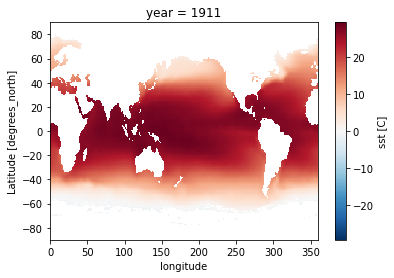

In [5]:
ds.sst[10].plot()

## 2. Build the data matrix Y (time × space) and remove the time mean

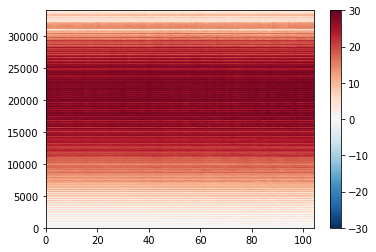

In [6]:
N, ny, nx = sst.shape
# each row = one year, each column = one grid point -- 3D to 2D (time X spatial grids)
Y = sst.reshape(N, ny * nx)
# keep ocean points only
ocean = np.all(np.isfinite(Y), axis=0)      
Y = Y[:, ocean]
#plt.plot(Y[0],'-')
plt.pcolormesh(Y.T,cmap=plt.cm.RdBu_r);
plt.clim([-30,30])
plt.colorbar();

N = 104 years, M = 34053 grid points


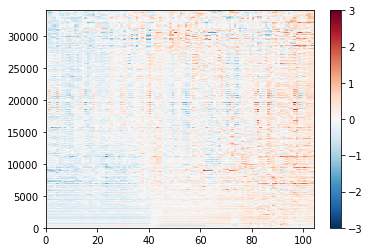

In [7]:
# anomalies: every column has zero mean 
Y = Y - Y.mean(axis=0)                      
M = Y.shape[1]
print(f"N = {N} years, M = {M} grid points")

plt.pcolormesh(Y.T,cmap=plt.cm.RdBu_r);
plt.clim([-3,3])
plt.colorbar();

## 3. Area weighting: multiply each column by sqrt(cos(lat))  

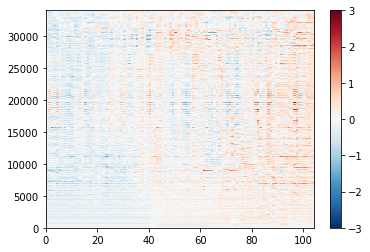

In [8]:
latgrid = np.repeat(lat, nx)[ocean]
w = np.sqrt(np.cos(np.deg2rad(latgrid)))     # W^(1/2)
Yw = Y * w
plt.pcolormesh(Yw.T,cmap=plt.cm.RdBu_r);
plt.clim([-3,3])
plt.colorbar();

## 4. SVD:  Yw = U S V^T
- U time series of the modes, it is the PC with magnitude removed


U: (104, 104)  s: (104,)  Vt: (104, 34053)


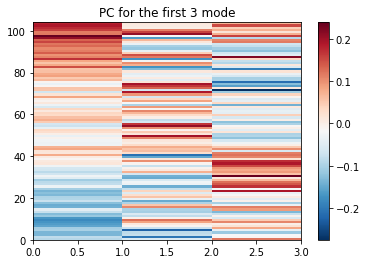

In [9]:
U, s, Vt = np.linalg.svd(Yw, full_matrices=False)
print("U:", U.shape, " s:", s.shape, " Vt:", Vt.shape)

plt.pcolormesh(U[:,:3],cmap=plt.cm.RdBu_r)
plt.title('PC for the first 3 mode')
plt.colorbar()

## 5. Variance explained

In [10]:
var_frac = s**2 / np.sum(s**2)  
# 1 standard error of varaince for Gaussian for large N ~ sigma*sqrt(2/N)
north_err = var_frac * np.sqrt(2/ N)        
for k in range(5):
    print(f"Mode {k+1}: {100*var_frac[k]:5.1f}% ± {100*north_err[k]:.1f}%")

Mode 1:  31.1% ± 4.3%
Mode 2:  20.0% ± 2.8%
Mode 3:   5.8% ± 0.8%
Mode 4:   4.8% ± 0.7%
Mode 5:   3.8% ± 0.5%


## 6. PCs and EOF maps
- **Vt** rows are the patterns (dimensionless, unit length). 
- **U** columns are their time series.
- Standardized PCs: **F = √(N−1) U** (unit variance)
- EOF maps in °C: regress the anomalies onto each standardized PC: **E = Yᵀ F / (N−1)**

In [11]:
def to_map(v):                                    # put ocean points back on the grid
    m = np.full(ny * nx, np.nan); m[ocean] = v
    return m.reshape(ny, nx)

In [12]:
K = 5
F = np.sqrt(N - 1) * U[:, :K]          # (N, K) standardized PCs
E = Vt[:K].T * s[:K] / np.sqrt(N - 1)   # (M, K) regression maps, °C per unit PC


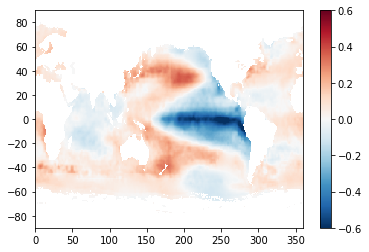

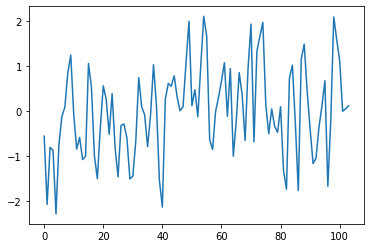

In [13]:
plt.pcolormesh(lon, lat, to_map(E[:, 1]), cmap="RdBu_r", vmin=-0.6, vmax=0.6)
plt.colorbar()

plt.figure()
plt.plot(F[:,1])
#plt.plot(U[:,0])

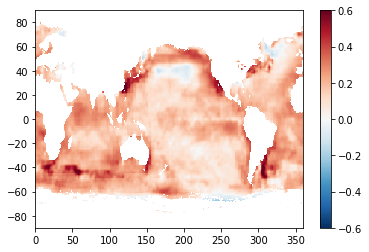

In [14]:
## alternatively, you can directly calculeate E by regress Y on the standardized PC
E1 = Y.T @ F / (N - 1) 
plt.pcolormesh(lon, lat, to_map(E1[:, 0]), cmap="RdBu_r", vmin=-0.6, vmax=0.6)
plt.colorbar()

## 7. Fix the arbitrary sign and find the ENSO mode (largest correlation with Niño 3.4)

In [15]:
lon_pts = np.tile(lon, ny)[ocean]
n34_pts = (np.abs(latgrid) <= 5) & (lon_pts >= 190) & (lon_pts <= 240)
nino34 = Y[:, n34_pts].mean(axis=1)

r = np.array([np.corrcoef(F[:, k], nino34)[0, 1] for k in range(K)])
kE = int(np.argmax(np.abs(r)))                   # ENSO-like mode
if r[kE] < 0:
    F[:, kE] *= -1; E[:, kE] *= -1               # positive = El Niño
    print('test')
if kE != 0 and F[-20:, 0].mean() < 0:            # make the trend mode warm at the end
    F[:, 0] *= -1; E[:, 0] *= -1
for k in range(K):
    print(f"r(PC{k+1}, Nino3.4) = {np.corrcoef(F[:, k], nino34)[0, 1]:+.2f}")



test
r(PC1, Nino3.4) = +0.27
r(PC2, Nino3.4) = +0.90
r(PC3, Nino3.4) = -0.13
r(PC4, Nino3.4) = +0.16
r(PC5, Nino3.4) = -0.04


## Check: plot the trend mode (index 0) and the ENSO mode (index kE)
After the sign fix, EOF1 should be warm almost everywhere and PC1 should rise over time;
the ENSO EOF should be warm in the equatorial Pacific, with PC peaks in El Niño years (e.g., 1941, 1982, 1997).

## Variance explained 

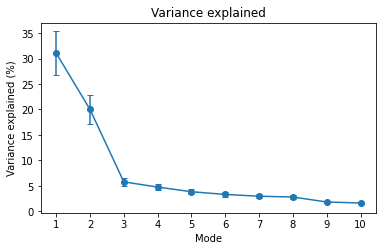

In [17]:
fig, ax = plt.subplots(figsize=(6, 3.5))
k = np.arange(1, 11)
ax.errorbar(k, 100*var_frac[:10], yerr=100*north_err[:10], fmt="o-", capsize=3)
ax.set_xlabel("Mode"); ax.set_ylabel("Variance explained (%)"); ax.set_xticks(k)
ax.set_title("Variance explained")
plt.show()

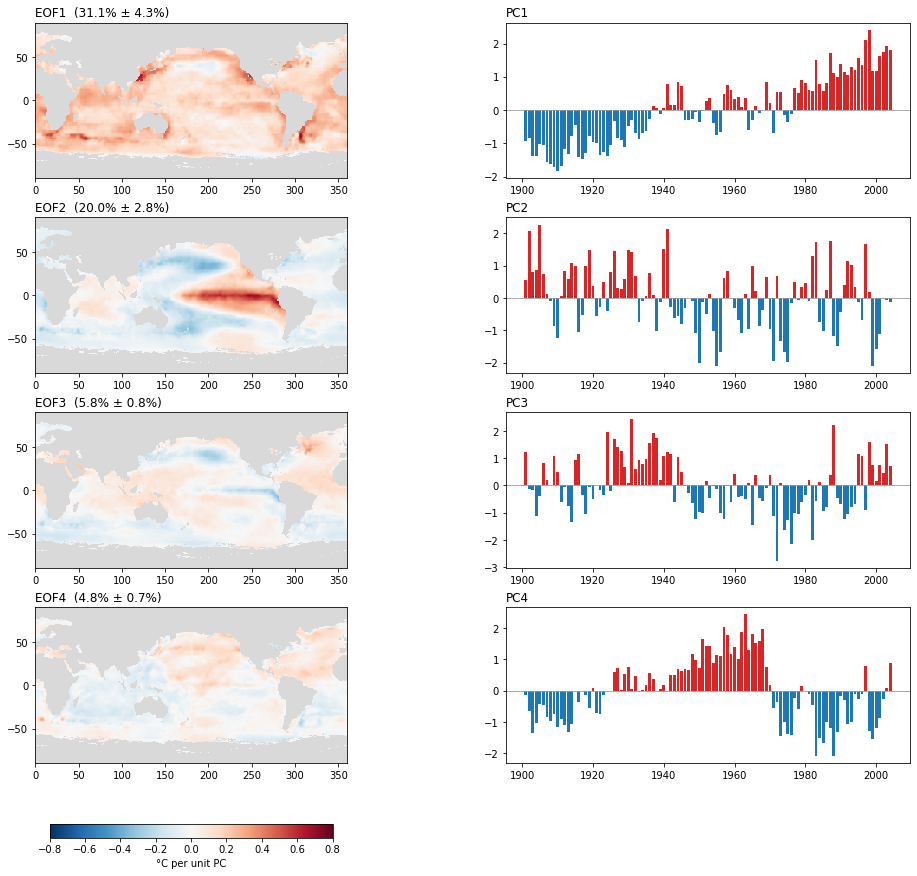

In [18]:
K = 4
fig, axs = plt.subplots(K, 2, figsize=(14, 3 * K), constrained_layout=True,
                        gridspec_kw={"width_ratios": [1.4, 1]})
for k in range(K):
    ax = axs[k, 0]; ax.set_facecolor("0.85")
    pm = ax.pcolormesh(lon, lat, to_map(E[:, k]), cmap="RdBu_r", vmin=-0.8, vmax=0.8)
    ax.set_aspect("equal")
    ax.set_title(f"EOF{k+1}  ({100*var_frac[k]:.1f}% ± {100*north_err[k]:.1f}%)", loc="left")

    ax = axs[k, 1]
    ax.bar(year, F[:, k], color=np.where(F[:, k] > 0, "tab:red", "tab:blue"))
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_title(f"PC{k+1}", loc="left")
fig.colorbar(pm, ax=axs[:, 0], location="bottom", shrink=0.5, label="°C per unit PC")
plt.show()

In [21]:
## check PC1 and correlation to global mean SST trend 
ds = xr.open_dataset("HadISST.nc")          # annual means, 1901–2004
sst  = ds["sst"].values                     # (year, lat, lon)
lat  = ds["latitude"].values
lon  = ds["longitude"].values

N, ny, nx = sst.shape
# each row = one year, each column = one grid point -- 3D to 2D (time X spatial grids)
Y = sst.reshape(N, ny * nx)
# keep ocean points only
ocean = np.all(np.isfinite(Y), axis=0)      
Y = Y[:, ocean]

# anomalies: every column has zero mean 
Y = Y - Y.mean(axis=0)        

latgrid = np.repeat(lat, nx)[ocean]
w = np.sqrt(np.cos(np.deg2rad(latgrid)))     # W^(1/2)
Yw = Y * w

gm_anomaly = Yw.mean(axis=1)
slope, intercept = np.polyfit(year, gm_anomaly, 1)
trend_line = slope * year + intercept
np.corrcoef(trend_line, F[:,0])[0,1]

0.8915920548505388